# ДЗ 3. Ошибки и устойчивость модели удовлетворённости пассажиров

В [ДЗ 2](02_model_and_ablation.ipynb) из пяти вариантов наибольший средний ROC-AUC показал E3: **0,958076**. Это LightGBM на исходных признаках и произведении оценок кресла и развлечений. На пяти исходных фолдах E3 опередила LightGBM без нового признака на 0,000037 ROC-AUC. По этим же фолдам мы выбрали E3. Воспроизводится ли эта разница на новых данных, пока неизвестно. [Таблица экспериментов](../reports/hw2/summary.csv) · [Настройки LightGBM](../configs/hw2.yaml)

Проверим, где E3 ошибается, насколько её оценка зависит от разбиения и что меняется, когда у модели меньше данных для обучения.

## Данные и протокол

Используем те же 699 635 строк, 21 исходный признак и 5 стратифицированных фолдов с seed 42, что и в ДЗ 2. OOF-прогноз для строки получаем на проверочной части её фолда. При обучении этой модели строка не участвовала. Скрипт сверяет хеш датасета, состав фолдов, ID, метки и метрики E3 с ДЗ 2. Произведение оценок считаем для каждой строки отдельно. Заполнение пропусков, стандартизацию и one-hot-кодирование настраиваем на обучающей части каждого фолда.

Условия обучения сравниваем по среднему ROC-AUC пяти фолдов. При разборе ошибок считаем прогноз положительным, если оценка модели не ниже 0,5. Калибровку оценок мы не проверяли.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if not (root / "reports/hw3").is_dir():
    root = root.parent
report = root / "reports/hw3"

def read(name):
    return pd.read_csv(report / f"{name}.csv")

def show(frame, precision=None):
    display(frame.style.hide(axis="index").format(precision or {}, decimal=",", thousands=" "))


## Четыре примера ошибок

Ошибки делим по направлению и оценке модели. Пограничный диапазон включает 0,4 и заканчивается перед 0,6. К краям шкалы относим оценки не выше 0,1 или не ниже 0,9. Остальные ошибки учитываем в сводке. FP обозначает ложноположительный прогноз, FN обозначает ложноотрицательный. Доли в таблице рассчитаны от общего числа ошибок.

In [2]:
counts = read("error_counts")
show(counts.rename(columns={"kind": "Ошибка", "band": "Диапазон", "n": "Число", "share_of_errors": "Доля"}),
     {"Доля": "{:.1%}"})
print(f"Всего ошибок: {counts.n.sum():,}".replace(",", " "))


Ошибка,Диапазон,Число,Доля
FN,Край шкалы,12 839,"24,6%"
FN,Между диапазонами,12 980,"24,8%"
FN,Около порога,4 141,"7,9%"
FP,Край шкалы,12 537,"24,0%"
FP,Между диапазонами,5 814,"11,1%"
FP,Около порога,3 971,"7,6%"


Всего ошибок: 52 282


В каждой из четырёх групп выбираем строку с оценкой модели, ближайшей к медиане группы. При равенстве берём меньший ID. В таблице приведены примеры без исходных ID. Для каждого примера считаем, как часто такая пара оценок услуг встречается среди ошибок того же диапазона и среди всех верных прогнозов. Сопоставляем поездки одного типа и класса обслуживания с одинаковым фактическим ответом. Диапазоны оценок кресла и развлечений заданы как 0–2, 3 и 4–5.

In [3]:
examples = read("error_examples")
cases = examples[["example", "error", "band", "target", "score", "travel", "service_class", "seat_band", "entertainment_band"]].copy()
cases["target"] = cases["target"].map({0: "Не удовлетворён", 1: "Удовлетворён"})
cases.columns = ["№", "Ошибка", "Диапазон", "Ответ", "Оценка модели", "Поездка", "Класс", "Кресло", "Развлечения"]
show(cases, {"Оценка модели": "{:.3f}"})
pattern = examples[["example", "same_pattern_errors", "n_errors", "same_pattern_correct", "n_correct"]].copy()
pattern["Доля среди ошибок"] = pattern.same_pattern_errors / pattern.n_errors
pattern["Доля среди верных"] = pattern.same_pattern_correct / pattern.n_correct
show(pattern.rename(columns={"example": "№", "same_pattern_errors": "Совпало (ошибки)", "n_errors": "Всего ошибок",
                             "same_pattern_correct": "Совпало (верные)", "n_correct": "Всего верных"}),
     {"Доля среди ошибок": "{:.1%}", "Доля среди верных": "{:.1%}"})


№,Ошибка,Диапазон,Ответ,Оценка модели,Поездка,Класс,Кресло,Развлечения
1,FP,Около порога,Не удовлетворён,"0,545",Деловая,Business,4–5,4–5
2,FP,Край шкалы,Не удовлетворён,"0,951",Деловая,Business,4–5,4–5
3,FN,Около порога,Удовлетворён,"0,452",Деловая,Business,3,0–2
4,FN,Край шкалы,Удовлетворён,"0,040",Личная,Eco,3,3


№,Совпало (ошибки),Всего ошибок,Совпало (верные),Всего верных,Доля среди ошибок,Доля среди верных
1,872,1 926,12 514,73 814,"45,3%","17,0%"
2,9 652,11 247,12 514,73 814,"85,8%","17,0%"
3,26,1 526,420,241 232,"1,7%","0,2%"
4,833,5 509,1 000,6 349,"15,1%","15,8%"


1. **FP около порога (0,545).** Среди неудовлетворённых пассажиров бизнес-класса в деловых поездках обе оценки попадают в диапазон 4–5 у 45,3% пограничных FP и у 17,0% правильно распознанных отрицательных ответов. Высокие оценки отдельных услуг могут сдвигать прогноз в сторону удовлетворённости, хотя итоговый ответ был отрицательным.
2. **FP на краю шкалы (0,951).** В той же группе обе оценки высокие у 85,8% FP на краю шкалы и у 17,0% верных отрицательных прогнозов. Связь между высокими оценками услуг и ошибкой здесь выражена сильнее, чем около порога. Чтобы измерить вклад именно произведения оценок, нужна отдельная проверка.
3. **FN около порога (0,452).** В деловых поездках бизнес-класса сочетание кресла с оценкой 3 и развлечений с оценкой 0–2 у удовлетворённых пассажиров встречается в 1,7% пограничных FN и в 0,2% верных положительных прогнозов. Сочетание чаще встречается в ошибках, хотя остаётся редким даже в этой группе. Низкие оценки услуг могли снизить прогноз и при положительном итоговом ответе.
4. **FN на краю шкалы (0,040).** В личных поездках экономкласса две оценки по 3 встречаются почти одинаково часто среди таких FN и верных положительных прогнозов (15,1% и 15,8%). Дополнительно проверили оценку онлайн-посадки из примера. Тройку поставили 31,1% пассажиров среди этих FN (1 715 из 5 509) и 2,4% среди верных прогнозов (151 из 6 349). Возможно, оценка онлайн-посадки вместе с другими признаками связана с низким прогнозом. Мы выбрали этот признак после просмотра примера, поэтому гипотезу ещё нужно проверить на других данных.

При пороге 0,5 модель допустила 52 282 ошибки. Из них 25 376 приходятся на края шкалы. Наблюдения по примерам помогают сформулировать гипотезы о признаках и контексте ошибки. Для проверки причин понадобились бы дополнительные данные об анкетах или отдельные эксперименты.

## Тип поездки и класс обслуживания

В каждом срезе рассчитываем ROC-AUC внутри каждого валидационного фолда и берём среднее пяти значений. ROC-AUC по объединённым OOF-прогнозам приводим для сопоставления с ДЗ 2. В нём также сравниваются оценки моделей из разных фолдов.

FNR показывает, какая доля фактически удовлетворённых получила отрицательный прогноз. FPR показывает, какая доля фактически неудовлетворённых получила положительный прогноз. Обе доли относятся к порогу 0,5.

Группа,Всего,Положительных,Отрицательных,"ROC-AUC, среднее","ROC-AUC, общий OOF",FN,FP,FN / положит.,FP / отрицат.
Деловая,497 441,290 673,206 768,"0,95355","0,95354",17 229,21 661,"5,9%","10,5%"
Личная,202 194,19 666,182 528,"0,82634","0,82618",12 731,661,"64,7%","0,4%"


Группа,Всего,Положительных,Отрицательных,"ROC-AUC, среднее","ROC-AUC, общий OOF",FN,FP,FN / положит.,FP / отрицат.
Business,342 212,248 210,94 002,"0,93306","0,93303",6 829,16 710,"2,8%","17,8%"
Eco,327 404,54 859,272 545,"0,90167","0,90163",21 170,4 944,"38,6%","1,8%"
Eco Plus,30 019,7 270,22 749,"0,92727","0,92727",1 961,668,"27,0%","2,9%"


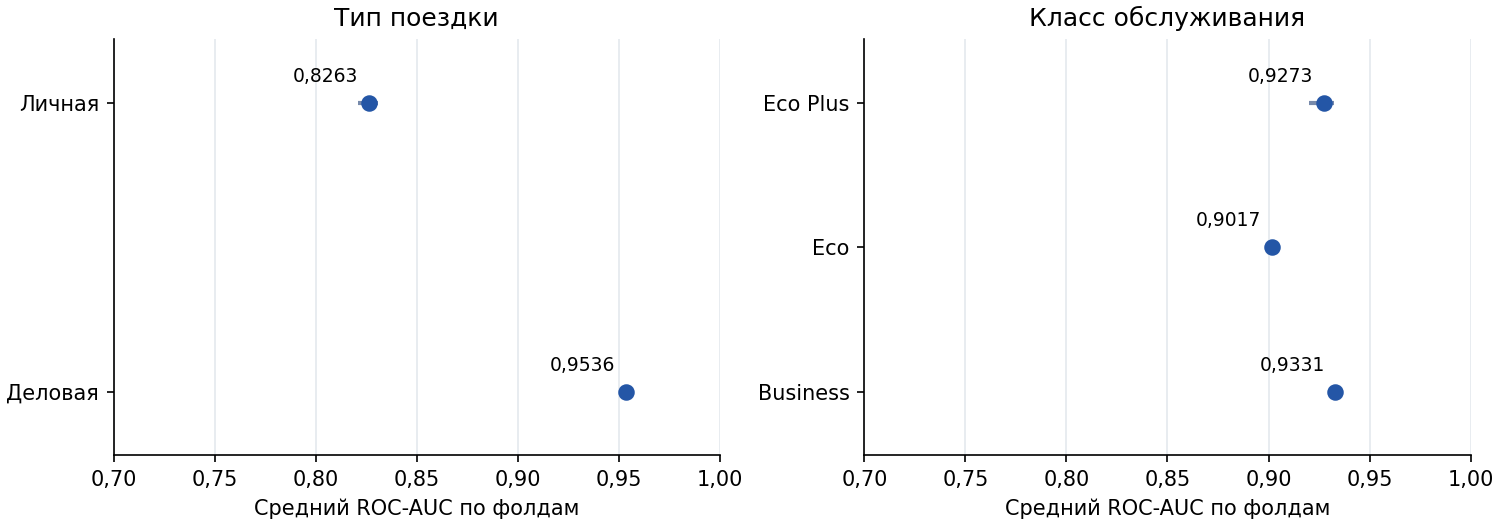

In [4]:
slices = read("slices")
for field in ("Type of Travel", "Class"):
    part = slices[slices.slice == field]
    show(part[["group", "n", "positive", "negative", "mean_fold_auc", "pooled_oof_auc", "fn", "fp", "fnr", "fpr"]].rename(columns={
        "group": "Группа", "n": "Всего", "positive": "Положительных", "negative": "Отрицательных",
        "mean_fold_auc": "ROC-AUC, среднее", "pooled_oof_auc": "ROC-AUC, общий OOF",
        "fn": "FN", "fp": "FP", "fnr": "FN / положит.", "fpr": "FP / отрицат."}),
        {"ROC-AUC, среднее": "{:.5f}", "ROC-AUC, общий OOF": "{:.5f}",
         "FN / положит.": "{:.1%}", "FP / отрицат.": "{:.1%}"})
display(Image(filename=str(report / "slices.png")))


Точки на графике показывают средний ROC-AUC. Отрезки соединяют минимум и максимум по пяти фолдам.

Средний ROC-AUC составил **0,9536** для деловых поездок и **0,8263** для личных. При пороге 0,5 модель пропускает 64,7% положительных ответов в личных поездках и 5,9% в деловых. При этом в личных поездках существенно ниже доля ложноположительных прогнозов (0,4% против 10,5%). Доля положительных ответов в группах тоже различается (9,7% в личных поездках и 58,4% в деловых). Для выбора рабочего порога понадобятся данные о цене каждого типа ошибки.

По классам обслуживания ROC-AUC ниже всего в Eco (0,9017 против 0,9331 в Business и 0,9273 в Eco Plus). Eco Plus заметно меньше остальных групп и показывает самый широкий разброс ROC-AUC по фолдам среди классов обслуживания. Срезы по классу и типу поездки перекрываются. Сравнения описывают различия в данных и поведении E3, а для объяснения этих различий нужно учитывать совместный состав групп.

## Две проверки устойчивости

**Смена разбиения.** Повторяем пятифолдовую оценку с seed разбиения 13 и 73. Исходная точка соответствует seed 42 из ДЗ 2. Seed самой модели всегда равен 42. Сравниваем средние по разбиениям. Фолды с одинаковым номером при разных seed содержат разные строки.

**Объём обучения.** На исходных фолдах берём 100%, 50% и 20% строк обучающей части каждого фолда. Для каждого класса отдельно перемешиваем индексы с фиксированным seed `20261124`, берём вложенные подвыборки и возвращаем исходный порядок строк. Предобработку и модель обучаем заново. Валидационные строки остаются теми же, поэтому для каждого фолда считаем парную разницу ROC-AUC относительно результата на полной обучающей части.

Seed разбиения,Средний ROC-AUC,Минимум,Максимум
42,"0,958076","0,956913","0,958732"
13,"0,958040","0,957365","0,958546"
73,"0,958062","0,957575","0,958597"


"Доля train, %",Мин. строк,Макс. строк,Средний ROC-AUC,Средняя разница,Мин. разница,Макс. разница
100,559 708,559 708,"0,958076","0,000000","0,000000","0,000000"
50,279 854,279 854,"0,957643","-0,000432","-0,000575","-0,000241"
20,111 941,111 941,"0,956958","-0,001118","-0,001339","-0,000949"


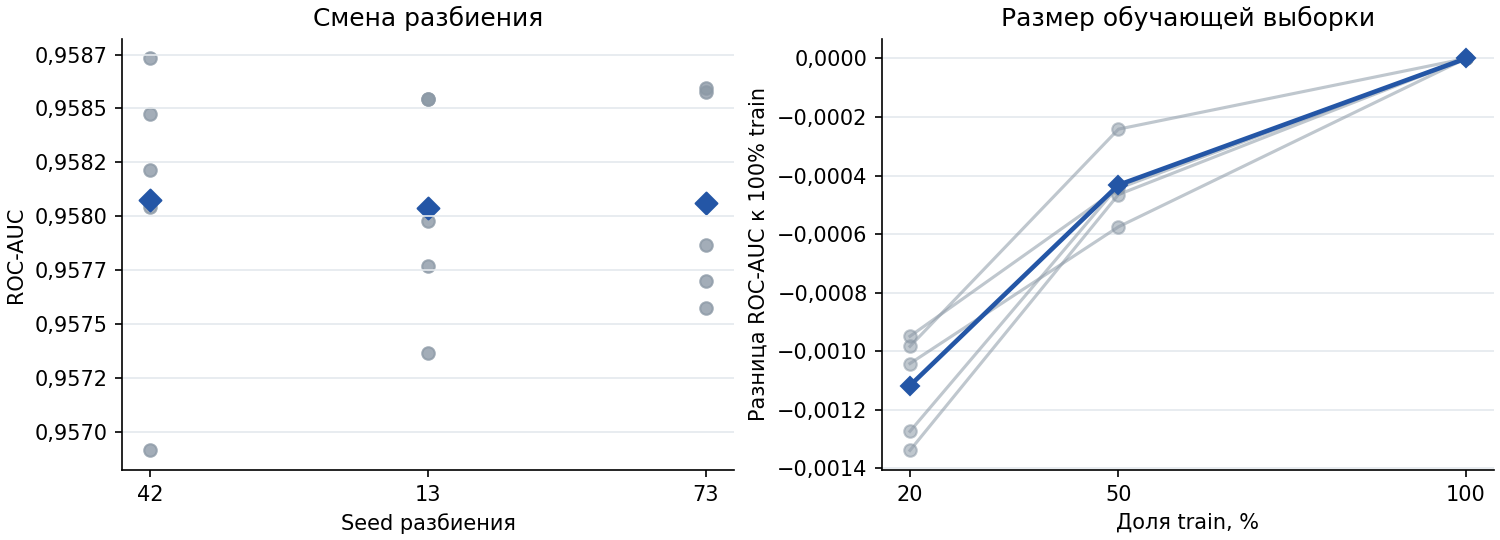

In [5]:
folds = read("robustness_folds")
full = folds[folds.train_fraction == 1]
by_seed = full.groupby("split_seed", sort=False).roc_auc.agg(["mean", "min", "max"]).reset_index()
by_seed.columns = ["Seed разбиения", "Средний ROC-AUC", "Минимум", "Максимум"]
show(by_seed, {column: "{:.6f}" for column in by_seed.columns[1:]})

by_size = (folds[folds.split_seed == 42].groupby("train_fraction", sort=False)
           .agg(n_train_min=("n_train", "min"), n_train_max=("n_train", "max"),
                auc=("roc_auc", "mean"), delta=("delta_vs_full", "mean"),
                low=("delta_vs_full", "min"), high=("delta_vs_full", "max")).reset_index())
by_size["train_fraction"] *= 100
by_size.columns = ["Доля train, %", "Мин. строк", "Макс. строк", "Средний ROC-AUC", "Средняя разница", "Мин. разница", "Макс. разница"]
show(by_size, {**{column: "{:.6f}" for column in by_size.columns[3:]}, "Доля train, %": "{:.0f}"})
display(Image(filename=str(report / "robustness.png")))


Слева серые точки показывают ROC-AUC отдельных фолдов. Синие ромбы обозначают среднее по разбиению. Справа серые линии показывают парные изменения внутри фолдов. Синяя линия показывает среднее этих изменений. Фолды частично используют одни и те же обучающие строки. Разброс описывает проведённые сравнения; для оценки статистической неопределённости потребовался бы другой протокол.

На трёх разбиениях с полным train средний ROC-AUC составил от **0,958040** до **0,958076**. Разница между крайними средними равна 0,000036.

При сокращении train до 50% средний ROC-AUC снизился на **0,000432**, а при сокращении до 20% на **0,001118**. Снижение наблюдалось на каждом из пяти исходных фолдов при обеих долях. Оценка относится к выбранным вложенным подвыборкам. Разные подвыборки одной и той же доли могут дать другой результат.

## Что следует из результатов

E3 слабее ранжирует ответы в личных поездках и в экономклассе. При пороге 0,5 модель пропускает почти две трети положительных ответов в личных поездках. Если задача требует находить такие ответы, качество в этой группе нужно проверять отдельно.

Смена разбиения и уменьшение train проверяют чувствительность E3 на одном синтетическом наборе. Для реального применения потребуются данные об анкетах другой выборки, оценка качества в нужных группах и выбор порога под цену ошибок. Оценки услуг могут стать доступны только после полёта или одновременно с целевой меткой. Для применения до полёта сначала нужно установить, какие признаки действительно доступны к моменту прогноза. Параметры предобработки мы вычисляли только по обучающей части фолда. Время появления признаков требует отдельной проверки.

В примерах связь между оценками услуг и ошибками помогает найти направления для диагностики. Причины отдельных ответов пассажиров, ошибки разметки и эффект каждого признака требуют дополнительных данных или контролируемых проверок.

## Воспроизведение

Ноутбук читает сохранённые агрегаты из `reports/hw3/`. Для повторного расчёта нужны зависимости и исходный `train.csv` с хешем из ДЗ 2. Скрипты строят исходный OOF для E3, запускают обе проверки и пересчитывают отчёт. Исходный OOF из ДЗ 2 можно использовать локально после сверки хеша. [Инструкция по запуску](../README.md#дз-3-ошибки-и-устойчивость-e3)